# Internal Audit Analytics — MEP Compliance & Risk Assessment
## Bagian 1: Compliance Analysis & Risk Identification

## Ringkasan Bisnis

**Tujuan Proyek:** Menganalisis data audit peralatan MEP (Lift, Escalator, Sprinkler, Genset, HVAC) di 10 site untuk mendukung dua fungsi inti pekerjaan Internal Audit:

1.  Memeriksa **kesesuaian implementasi prosedur maintenance di lapangan** dibandingkan standar yang ditetapkan.
2.  **Mengidentifikasi dan mengevaluasi potensi risiko/pelanggaran** untuk memprioritaskan fokus audit berikutnya.

**Signifikansi Bisnis:** Peralatan MEP yang tidak dirawat sesuai prosedur berisiko menyebabkan kegagalan fungsi (lift terhenti, sprinkler tidak aktif saat kebakaran, genset gagal saat listrik padam) — dampaknya bukan hanya finansial, tapi juga keselamatan jiwa. Analisis ini membantu tim audit menentukan **site dan kategori peralatan mana yang butuh perhatian paling besar**, berdasarkan data historis, bukan asumsi.

**Dataset:** `MEP_Internal_Audit_Dataset.csv` — 1.251 catatan audit dari 217 unit peralatan di 10 site, periode Q1 2023 – Q4 2024.

----

## Import Data

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/sample_data/MEP_Internal_Audit_Dataset.csv')
df.head()

,Audit_ID,Audit_Date,Audit_Quarter,Site_ID,Site_Name,Site_Type,City,Equipment_ID,Equipment_Category,Equipment_Age_Years,...,Finding_Category,Risk_Level,Is_Repeat_Finding,Requires_Investigation,Investigation_Status,Corrective_Action,Days_To_Resolve,Estimated_Financial_Exposure_IDR,Follow_Up_Status,Auditor_Name
0,AUD-2023-00001,2023-01-22,Q1 2023,SITE-01,Menara Graha Utama,Office Tower,Jakarta Selatan,EQ-0001,Lift,14,...,Ketersediaan Spare Part,Medium,No,No,Tidak Berlaku,Dalam Proses,17.0,29599749,Open,Andi Pratama
1,AUD-2023-00002,2023-01-28,Q1 2023,SITE-01,Menara Graha Utama,Office Tower,Jakarta Selatan,EQ-0002,Lift,12,...,Tidak Ada Temuan,Low,No,No,Tidak Berlaku,Tidak Berlaku,NaN,0,Closed,Nadia Putri
2,AUD-2023-00003,2023-02-18,Q1 2023,SITE-01,Menara Graha Utama,Office Tower,Jakarta Selatan,EQ-0003,Lift,8,...,Deviasi Prosedur Maintenance,Medium,No,No,Tidak Berlaku,Selesai,6.0,39788757,Closed,Andi Pratama
3,AUD-2023-00004,2023-02-23,Q1 2023,SITE-01,Menara Graha Utama,Office Tower,Jakarta Selatan,EQ-0004,Escalator,15,...,Tidak Ada Temuan,Low,No,No,Tidak Berlaku,Tidak Berlaku,NaN,0,Closed,Siti Rahma
4,AUD-2023-00005,2023-01-08,Q1 2023,SITE-01,Menara Graha Utama,Office Tower,Jakarta Selatan,EQ-0005,Escalator,2,...,Tidak Ada Temuan,Low,No,No,Tidak Berlaku,Tidak Berlaku,NaN,0,Closed,Siti Rahma


## 2. Data Understanding

Dataset `MEP_Internal_Audit_Dataset.csv` berisi 1.251 catatan audit dengan 21 kolom. Berikut adalah penjelasan untuk kolom-kolom kunci yang relevan dengan tujuan analisis:

-   `Audit_Date`: Tanggal dilakukannya audit. Ini penting untuk analisis tren waktu.
-   `Audit_Quarter`: Kuartal audit (misalnya Q1 2023, Q2 2023). Digunakan sebagai dimensi waktu agregat.
-   `Site_Name`: Nama lokasi (site) yang diaudit. Penting untuk analisis per site.
-   `Site_Type`: Tipe lokasi (misalnya Office Tower, Mall). Memberikan konteks tambahan tentang site.
-   `Equipment_Category`: Kategori peralatan yang diaudit (misalnya Lift, Escalator, Genset, HVAC, Sprinkler). Penting untuk analisis per kategori peralatan.
-   `Equipment_Age_Years`: Usia peralatan dalam tahun. Berpotensi berkorelasi dengan tingkat risiko atau kepatuhan.
-   `Maintenance_Compliance`: Status kepatuhan maintenance (`Compliant`, `Non-Compliant`). Ini adalah target utama untuk **Analisis 1: Compliance Analysis**.
-   `Risk_Level`: Tingkat risiko yang ditemukan (`Low`, `Medium`, `High`, `Critical`). Ini adalah target utama untuk **Analisis 2: Risk Identification**.
-   `Finding_Category`: Kategori temuan audit (misalnya Ketersediaan Spare Part, Defek Teknis, Deviasi Prosedur). Memberikan detail tentang jenis masalah yang ditemukan.

In [7]:
# Cek jumlah baris dan kolom
print(f"Shape of the DataFrame: {df.shape}")

# Cek tipe data dan informasi non-null
df.info()

Shape of the DataFrame: (1251, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1251 entries, 0 to 1250
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Audit_ID                          1251 non-null   object 
 1   Audit_Date                        1251 non-null   object 
 2   Audit_Quarter                     1251 non-null   object 
 3   Site_ID                           1251 non-null   object 
 4   Site_Name                         1251 non-null   object 
 5   Site_Type                         1251 non-null   object 
 6   City                              1251 non-null   object 
 7   Equipment_ID                      1251 non-null   object 
 8   Equipment_Category                1251 non-null   object 
 9   Equipment_Age_Years               1251 non-null   int64  
 10  Maintenance_Compliance            1251 non-null   object 
 11  Finding_Category                  

### Insight dari `df.shape` dan `df.info()`:

-   **Ukuran Dataset:** Dataset ini memiliki 1251 baris (catatan audit) dan 21 kolom. Ukuran ini cukup memadai untuk analisis.
-   **Tipe Data:** Sebagian besar kolom memiliki tipe data `object` (string), yang merupakan hal yang wajar untuk data kategorikal atau teks. Kolom `Audit_Date` sudah dideteksi sebagai `object`, yang perlu diubah ke tipe `datetime` agar bisa dilakukan analisis waktu.
-   **Missing Values (Sekilas):** Dari `df.info()`, kita bisa melihat ada beberapa kolom yang jumlah non-null-nya kurang dari 1251, menandakan adanya missing values. Kolom `Days_To_Resolve` memiliki jumlah non-null yang paling sedikit (381), yang kemungkinan besar terkait dengan kasus audit yang tidak memiliki temuan (`Tidak Ada Temuan`) atau tidak memerlukan tindak lanjut (`Tidak Berlaku`), sehingga kolom ini wajar jika kosong.
-   **Kolom Numerik:** `Equipment_Age_Years` dan `Estimated_Financial_Exposure_IDR` adalah numerik (`int64`), yang akan berguna untuk analisis kuantitatif.

In [8]:
# Cek missing values secara detail
df.isnull().sum()

,0
Audit_ID,0
Audit_Date,0
Audit_Quarter,0
Site_ID,0
Site_Name,0
Site_Type,0
City,0
Equipment_ID,0
Equipment_Category,0
Equipment_Age_Years,0


### Insight dari `df.isnull().sum()`:

-   **`Days_To_Resolve`:** Ada 870 missing values. Ini sesuai dengan ekspektasi karena kolom ini hanya relevan jika ada temuan yang memerlukan penyelesaian. Audit tanpa temuan atau temuan yang tidak memerlukan tindakan spesifik akan memiliki nilai kosong di sini. Kolom ini mungkin akan diabaikan atau ditangani secara khusus jika digunakan dalam analisis yang berfokus pada waktu penyelesaian temuan.
-   **`Estimated_Financial_Exposure_IDR`:** Meskipun `df.info()` menunjukkan 1251 non-null, `isnull().sum()` tidak melaporkan missing values, yang berarti semua baris memiliki nilai (bisa jadi 0, seperti yang terlihat di `df.head()`).
-   **Tidak Ada Missing Value Kritis:** Kolom-kolom kunci seperti `Audit_Date`, `Site_Name`, `Equipment_Category`, `Maintenance_Compliance`, dan `Risk_Level` tidak memiliki missing values. Ini sangat baik karena kolom-kolom ini adalah inti dari analisis kita.

## 3. Data Cleaning

In [9]:
#Konversi Audit_Date ke tipe datetime
df['Audit_Date'] = pd.to_datetime(df['Audit_Date'])

# Buat kolom bantu Audit_Quarter_Sort untuk pengurutan kronologis
# Kita bisa mengekstrak tahun dan kuartal dari Audit_Date
# Contoh: Q1 2023 -> (2023, 1)
df['Audit_Quarter_Sort'] = df['Audit_Date'].dt.to_period('Q')

print("Kolom 'Audit_Date' setelah konversi:")
print(df['Audit_Date'].head())
print("\nKolom 'Audit_Quarter_Sort' yang baru dibuat:")
print(df['Audit_Quarter_Sort'].head())
print("\nTipe data 'Audit_Date' dan 'Audit_Quarter_Sort' setelah perubahan:")
print(df[['Audit_Date', 'Audit_Quarter_Sort']].dtypes)

Kolom 'Audit_Date' setelah konversi:
0   2023-01-22
1   2023-01-28
2   2023-02-18
3   2023-02-23
4   2023-01-08
Name: Audit_Date, dtype: datetime64[ns]

Kolom 'Audit_Quarter_Sort' yang baru dibuat:
0    2023Q1
1    2023Q1
2    2023Q1
3    2023Q1
4    2023Q1
Name: Audit_Quarter_Sort, dtype: period[Q-DEC]

Tipe data 'Audit_Date' dan 'Audit_Quarter_Sort' setelah perubahan:
Audit_Date            datetime64[ns]
Audit_Quarter_Sort     period[Q-DEC]
dtype: object


In [10]:
# Cek nilai unik pada kolom-kolom kategorikal penting
print("Nilai unik pada 'Maintenance_Compliance':")
print(df['Maintenance_Compliance'].unique())

print("\nNilai unik pada 'Risk_Level':")
print(df['Risk_Level'].unique())

print("\nNilai unik pada 'Equipment_Category':")
print(df['Equipment_Category'].unique())

print("\nNilai unik pada 'Site_Name':")
print(df['Site_Name'].unique())

Nilai unik pada 'Maintenance_Compliance':
['Non-Compliant' 'Compliant']

Nilai unik pada 'Risk_Level':
['Medium' 'Low' 'Critical' 'High']

Nilai unik pada 'Equipment_Category':
['Lift' 'Escalator' 'Sprinkler' 'Genset' 'HVAC']

Nilai unik pada 'Site_Name':
['Menara Graha Utama' 'Plaza Sentral Mall' 'RS Harapan Sehat'
 'Apartemen Kirana Residence' 'Gudang Logistik Cikarang'
 'Hotel Grand Meridian' 'Menara Bisnis Selatan' 'Mall Kota Baru'
 'Apartemen Green Valley' 'RS Medika Utama']


## 4. Analisis-1


### 4.1 Analisis Compilance Keseluruhan


Jumlah Maintenance Compilance Keseluruhan:
Maintenance_Compliance
Compliant        626
Non-Compliant    625
Name: count, dtype: int64

Distribusi Maintenance Compilance Keseluruhan (Rate):
Maintenance_Compliance
Compliant        50.04
Non-Compliant    49.96
Name: proportion, dtype: float64


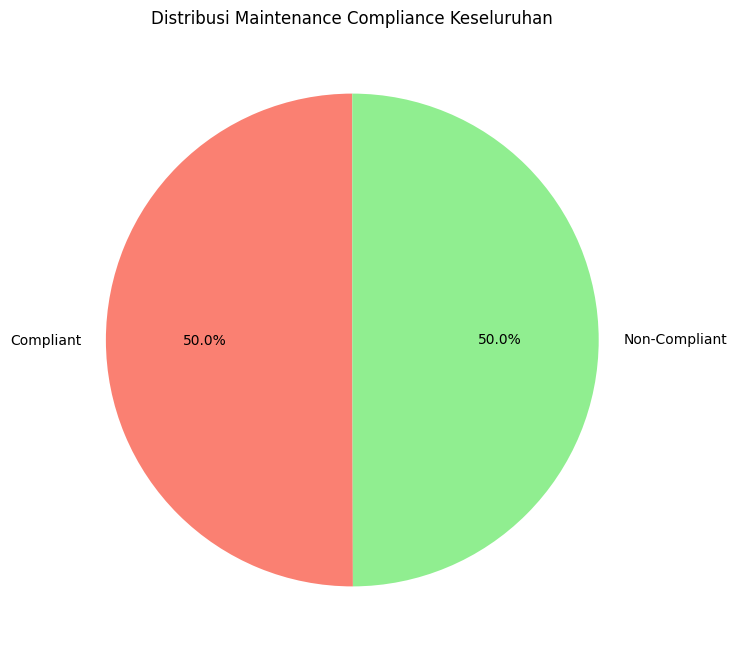

In [11]:
#Hitung value_counts pada Maintenance_Compilance dan normalisasi
compilance = df['Maintenance_Compliance'].value_counts()
print('Jumlah Maintenance Compilance Keseluruhan:')
print(compilance)
compilance_rate = df['Maintenance_Compliance'].value_counts(normalize=True).mul(100).round(2)
print('\nDistribusi Maintenance Compilance Keseluruhan (Rate):')
print(compilance_rate)

#Visualisasi
plt.figure(figsize=(8, 8))
plt.pie(compilance_rate, labels=compilance_rate.index, autopct='%1.1f%%', startangle=90, colors=['salmon', 'lightgreen'])
plt.title('Distribusi Maintenance Compliance Keseluruhan')
plt.show()


### 4.2 Compilance Rate per Site

Proporsi Non-Compliant per Site_Name:
Site_Name
RS Harapan Sehat              65.060241
Gudang Logistik Cikarang      63.281250
Apartemen Green Valley        61.983471
Plaza Sentral Mall            50.000000
RS Medika Utama               48.120301
Menara Bisnis Selatan         47.656250
Mall Kota Baru                41.463415
Apartemen Kirana Residence    40.769231
Menara Graha Utama            38.297872
Hotel Grand Meridian          34.745763
Name: Non-Compliant, dtype: float64


/tmp/ipykernel_1160/3307137072.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=site_non_compliance_rate.values, y=site_non_compliance_rate.index, palette='Reds_d')


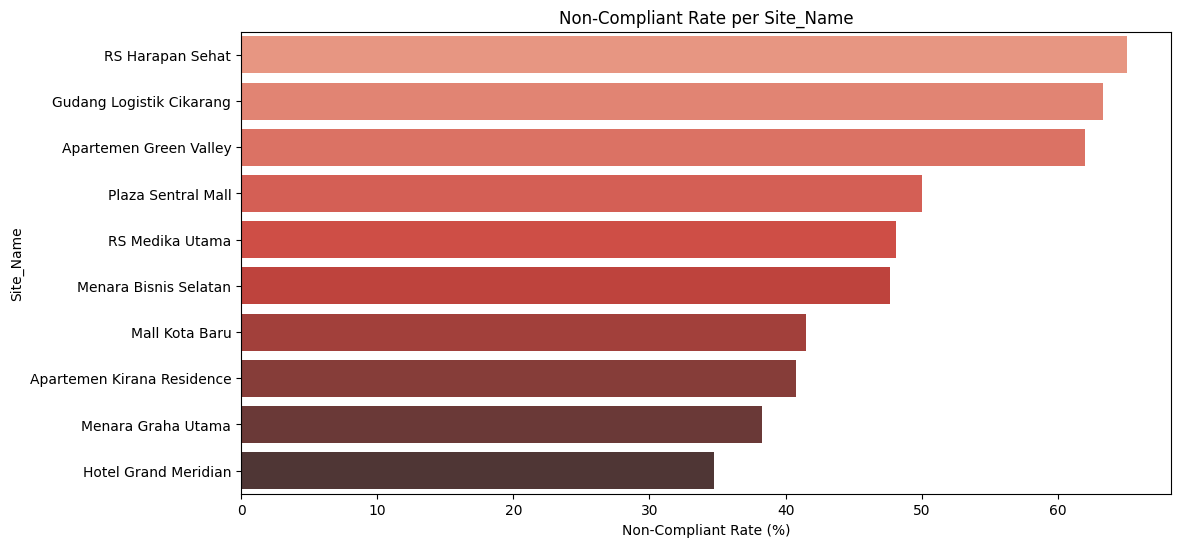

In [12]:
#Hitung proporsi Non-Compilant per Site_Name
site_compliance = df.groupby('Site_Name')['Maintenance_Compliance'].value_counts(normalize=True).unstack(fill_value=0)

if 'Non-Compliant' not in site_compliance.columns:
    site_compliance['Non-Compliant'] = 0.0

site_non_compliance_rate = site_compliance['Non-Compliant'].mul(100).sort_values(ascending=False)

print('Proporsi Non-Compliant per Site_Name:')
print(site_non_compliance_rate)

#Visualisasi
plt.figure(figsize=(12, 6))
sns.barplot(x=site_non_compliance_rate.values, y=site_non_compliance_rate.index, palette='Reds_d')
plt.title('Non-Compliant Rate per Site_Name')
plt.xlabel('Non-Compliant Rate (%)')
plt.ylabel('Site_Name')
plt.show()

### 4.3 Comliance Rate per Equipment Category

Proporsi Non-Compliant per Equipment Category:
Equipment_Category
Genset       56.190476
HVAC         56.185567
Sprinkler    49.433962
Lift         49.068323
Escalator    34.502924
Name: Non-Compliant, dtype: float64


/tmp/ipykernel_1160/1997282517.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=equipment_non_comp_rate.values, y=equipment_non_comp_rate.index, palette='Blues_d')


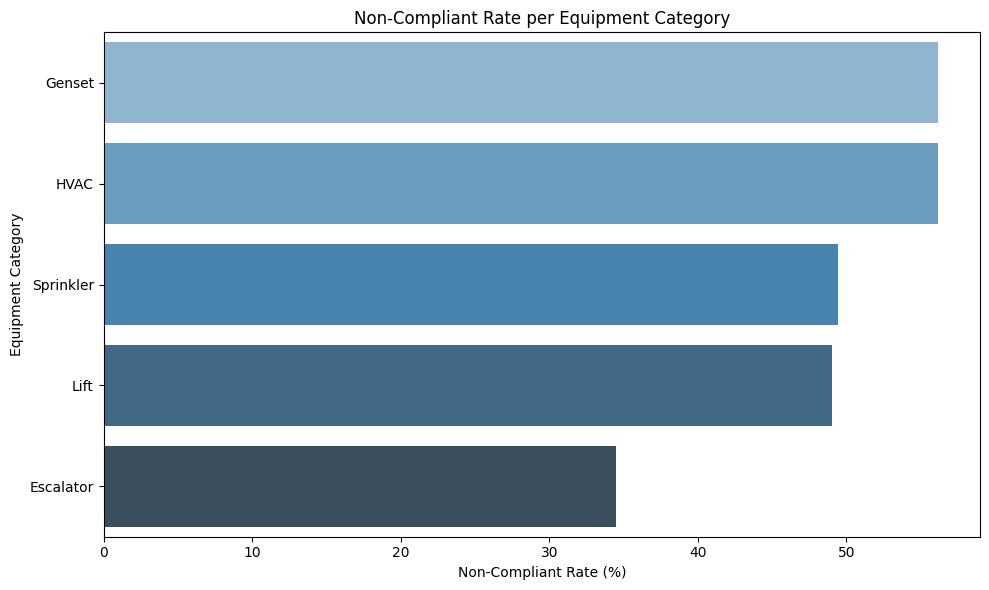

In [13]:
#Hitung proportsi Non-Compliant per Equipment
equipment_comp = df.groupby('Equipment_Category')['Maintenance_Compliance'].value_counts(normalize=True).unstack(fill_value=0)

equipment_non_comp_rate = equipment_comp['Non-Compliant'].mul(100).sort_values(ascending=False)

print('Proporsi Non-Compliant per Equipment Category:')
print(equipment_non_comp_rate)

#Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(x=equipment_non_comp_rate.values, y=equipment_non_comp_rate.index, palette='Blues_d')
plt.title('Non-Compliant Rate per Equipment Category')
plt.xlabel('Non-Compliant Rate (%)')
plt.ylabel('Equipment Category')
plt.tight_layout()
plt.show()

### 4.4 Tren Compliance dari Waktu ke Waktu

  Audit_Quarter_Sort  Non-Compliant
0             2023Q1      41.721854
1             2023Q2      52.903226
2             2023Q3      57.046980
3             2023Q4      53.333333
4             2024Q1      51.479290
5             2024Q2      50.000000
6             2024Q3      46.835443
7             2024Q4      46.405229


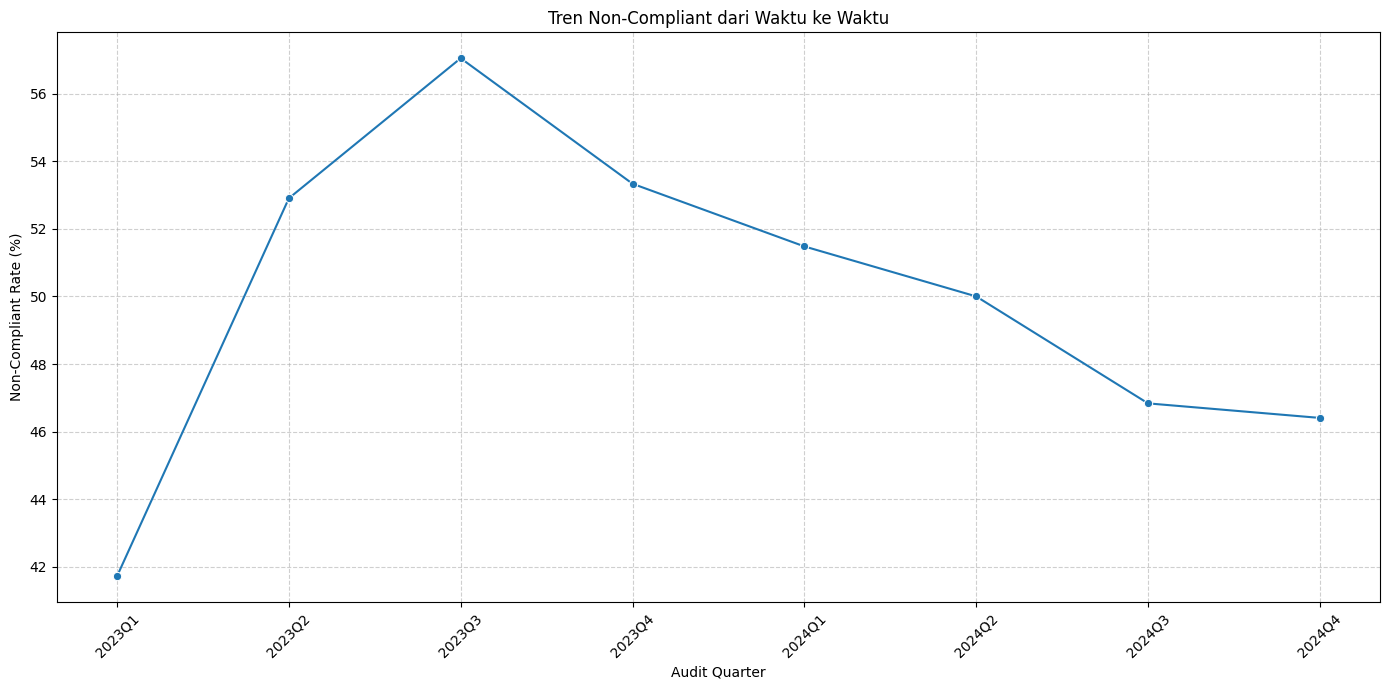

In [14]:
# Hitung proporsi Non-Compliant per Audit_Quarter_Sort
# Pastikan Audit_Quarter_Sort diurutkan secara kronologis
quarterly_comp = df.groupby('Audit_Quarter_Sort')['Maintenance_Compliance'].value_counts(normalize=True).unstack(fill_value=0)

quarterly_non_comp_rate = quarterly_comp['Non-Compliant'].mul(100).reset_index()

print(quarterly_non_comp_rate)

#Ubah tipe data Audit_Quarter_Sort ke string
quarterly_non_comp_rate['Audit_Quarter_Sort'] = quarterly_non_comp_rate['Audit_Quarter_Sort'].astype(str)

#Visualisasi
plt.figure(figsize=(14, 7))
sns.lineplot(x='Audit_Quarter_Sort', y='Non-Compliant', data=quarterly_non_comp_rate, marker='o')
plt.title('Tren Non-Compliant dari Waktu ke Waktu')
plt.xlabel('Audit Quarter')
plt.ylabel('Non-Compliant Rate (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.5 Insight Komprehensif dari Analisis Compliance:

Berdasarkan analisis yang telah kita lakukan pada bagian Compliance ini, beberapa *insight* penting dapat kita simpulkan:

1.  **Compliance Keseluruhan Cukup Berimbang:** Tingkat kepatuhan (Compliant) dan ketidakpatuhan (Non-Compliant) secara keseluruhan hampir seimbang, masing-masing sekitar 50%. Ini menunjukkan bahwa ada potensi besar untuk peningkatan kepatuhan yang signifikan.
2.  **Variasi Compliance Antar Lokasi (Site):** Terdapat perbedaan yang mencolok dalam tingkat ketidakpatuhan di antara berbagai lokasi. Beberapa lokasi seperti **RS Harapan Sehat (65.06%)**, **Gudang Logistik Cikarang (63.28%)**, dan **Apartemen Green Valley (61.98%)** menunjukkan tingkat `Non-Compliant` yang sangat tinggi. Ini mengindikasikan bahwa masalah kepatuhan mungkin lebih terkonsentrasi pada lokasi-lokasi tertentu dan memerlukan perhatian serta intervensi yang lebih fokus.
3.  **Kategori Peralatan dengan Risiko Compliance Tinggi:** Peralatan kategori **Genset (56.19%)** dan **HVAC (56.18%)** memiliki *Non-Compliant Rate* tertinggi. Ini menunjukkan bahwa perawatan atau prosedur operasional untuk jenis peralatan ini mungkin memerlukan perbaikan atau pengawasan yang lebih ketat dibandingkan dengan kategori peralatan lain seperti Escalator yang memiliki tingkat ketidakpatuhan terendah (34.50%).
4.  **Tren Non-Compliant yang Berfluktuasi:**
    *   Pada awal periode (Q1 2023), tingkat *Non-Compliant* sekitar **41.72%**. Namun, ini meningkat tajam hingga mencapai puncaknya di **Q3 2023 (57.05%)**, yang merupakan titik kritis yang perlu diinvestigasi lebih lanjut.
    *   Setelah Q3 2023, ada tren penurunan tingkat *Non-Compliant* yang bertahap hingga **Q4 2024 (46.41%)**. Penurunan ini bisa jadi indikasi dari adanya perbaikan atau intervensi yang mulai membuahkan hasil, meskipun tingkatnya masih lebih tinggi dari Q1 2023.

### Implikasi Audit:

*   **Prioritas Lokasi:** Audit internal harus memprioritaskan audit di **RS Harapan Sehat, Gudang Logistik Cikarang, dan Apartemen Green Valley**. Diperlukan investigasi mendalam untuk memahami akar masalah ketidakpatuhan di sana.
*   **Prioritas Peralatan:** Fokus pada prosedur perawatan dan kepatuhan untuk **Genset dan HVAC**.
*   **Analisis Tren Lebih Lanjut:** Puncak `Non-Compliant Rate` di Q3 2023 harus ditelusuri. Apakah ada perubahan kebijakan, masalah sumber daya, atau peristiwa tertentu yang memicu peningkatan tersebut?

## 5. Analisis-2

### 5.1 Distribusi Risk Level Keseluruhan

Distribusi Risk Level Keseluruhan:
Risk_Level
Low         701
Medium      202
High        216
Critical    132
Name: count, dtype: int64


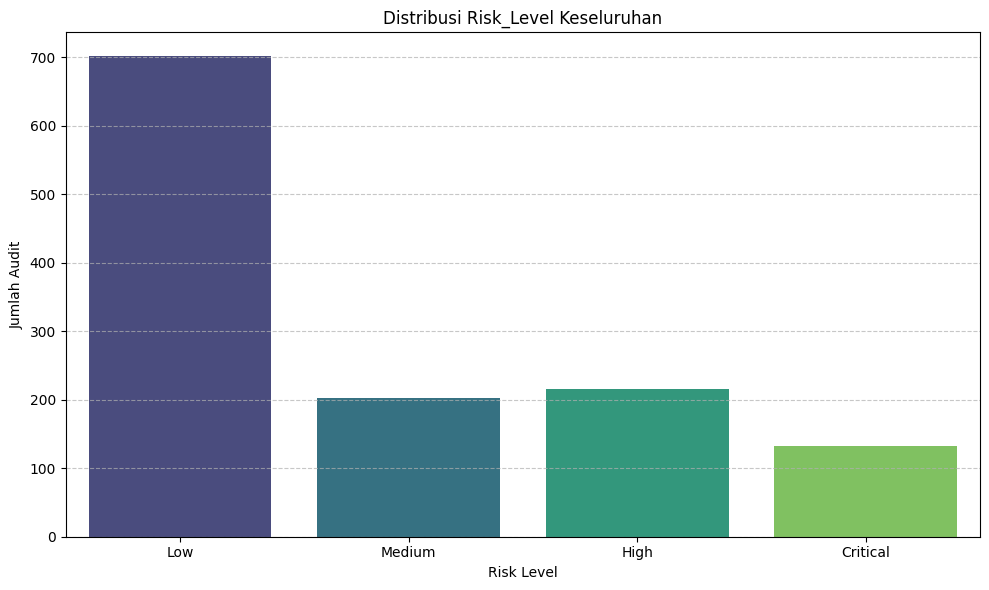

In [15]:
#Tentukan urutan kategori Risk_Level
risk_level_order = ['Low', 'Medium', 'High', 'Critical']

#Konversi type data kolom Risk_Level ke kategorikal
df['Risk_Level'] = pd.Categorical(df['Risk_Level'], categories=risk_level_order, ordered=True)

#Hitung value_counts pada Risk_Level
risk_level_counts = df['Risk_Level'].value_counts().sort_index()

print('Distribusi Risk Level Keseluruhan:')
print(risk_level_counts)

#Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(x=risk_level_counts.index, y=risk_level_counts.values, palette='viridis',
            hue=risk_level_counts.index, legend=False)
plt.title('Distribusi Risk_Level Keseluruhan')
plt.xlabel('Risk Level')
plt.ylabel('Jumlah Audit')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 5.2 Risk Matrix: Site x Equipment_Category

Risk Matrix (Proporsi High/Critical Risk per Site dan Equipment Category:)


Equipment_Category,Escalator,Genset,HVAC,Lift,Sprinkler
Site_Name,,,,,
Apartemen Green Valley,16.67,50.00,45.61,22.22,50.00
Apartemen Kirana Residence,16.67,40.00,26.32,19.57,30.56
Gudang Logistik Cikarang,20.00,63.64,31.71,30.00,57.14
Hotel Grand Meridian,21.74,25.00,12.50,9.38,29.63
Mall Kota Baru,30.00,41.67,15.38,25.00,21.95
Menara Bisnis Selatan,15.38,6.67,21.15,21.62,54.55
Menara Graha Utama,0.00,26.67,23.81,17.65,20.69
Plaza Sentral Mall,28.57,33.33,21.28,16.00,18.18
RS Harapan Sehat,42.86,53.85,33.33,28.89,45.95


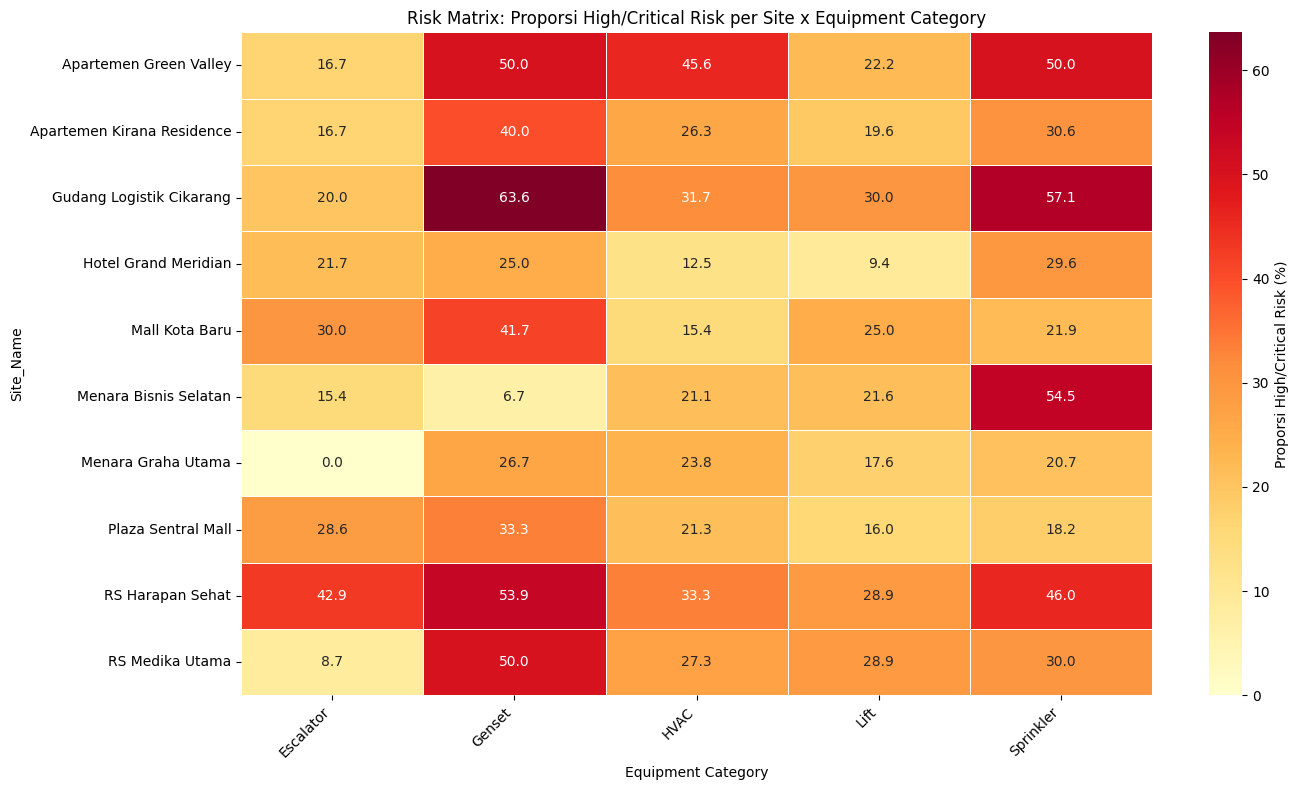

In [17]:
#Buat kolom bantu biner: Is_High_Risk (True jika Risk_Level = High atau Critical)
df['Is_High_Risk'] = df['Risk_Level'].isin(['High', 'Critical'])

# Buat pivot table untuk Risk Matrix
# Menghitung proporsi audit High/Critical per kombinasi Site_Name dan Equipment_Category
risk_matrix = pd.crosstab(
    index=df['Site_Name'],
    columns=df['Equipment_Category'],
    values=df['Is_High_Risk'],
    aggfunc='mean'
).mul(100).round(2)

print('Risk Matrix (Proporsi High/Critical Risk per Site dan Equipment Category:)')
display(risk_matrix)

#Visualisasi
plt.figure(figsize=(14, 8))
sns.heatmap(risk_matrix, annot=True, cmap='YlOrRd', fmt='.1f', linewidths=.5,
            cbar_kws={'label': 'Proporsi High/Critical Risk (%)'})
plt.title('Risk Matrix: Proporsi High/Critical Risk per Site x Equipment Category')
plt.xlabel('Equipment Category')
plt.ylabel('Site_Name')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.3 Hubungan Usia Peralatan dengan Risiko

/tmp/ipykernel_1160/3631347484.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Risk_Level', y='Equipment_Age_Years', data=df, palette='coolwarm', order=risk_level_order)


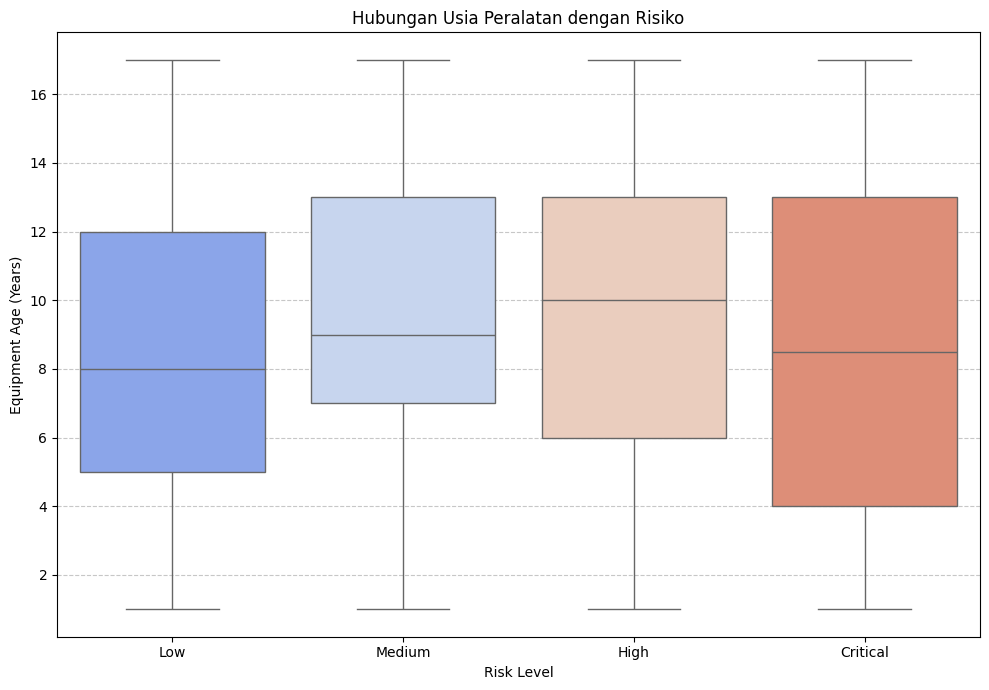

In [19]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='Risk_Level', y='Equipment_Age_Years', data=df, palette='coolwarm', order=risk_level_order)
plt.title('Hubungan Usia Peralatan dengan Risiko')
plt.xlabel('Risk Level')
plt.ylabel('Equipment Age (Years)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 5.4 Kategori Temuan Paling Sering Memicu Risiko Tinggi

Kategori Temuan Paling Sering Memicu Risiko Tinggi:
Finding_Category
Dokumentasi Tidak Lengkap       101
Defek Teknis/Safety              90
Deviasi Prosedur Maintenance     84
Sertifikasi/Izin Kadaluarsa      37
Ketersediaan Spare Part          36
Name: count, dtype: int64


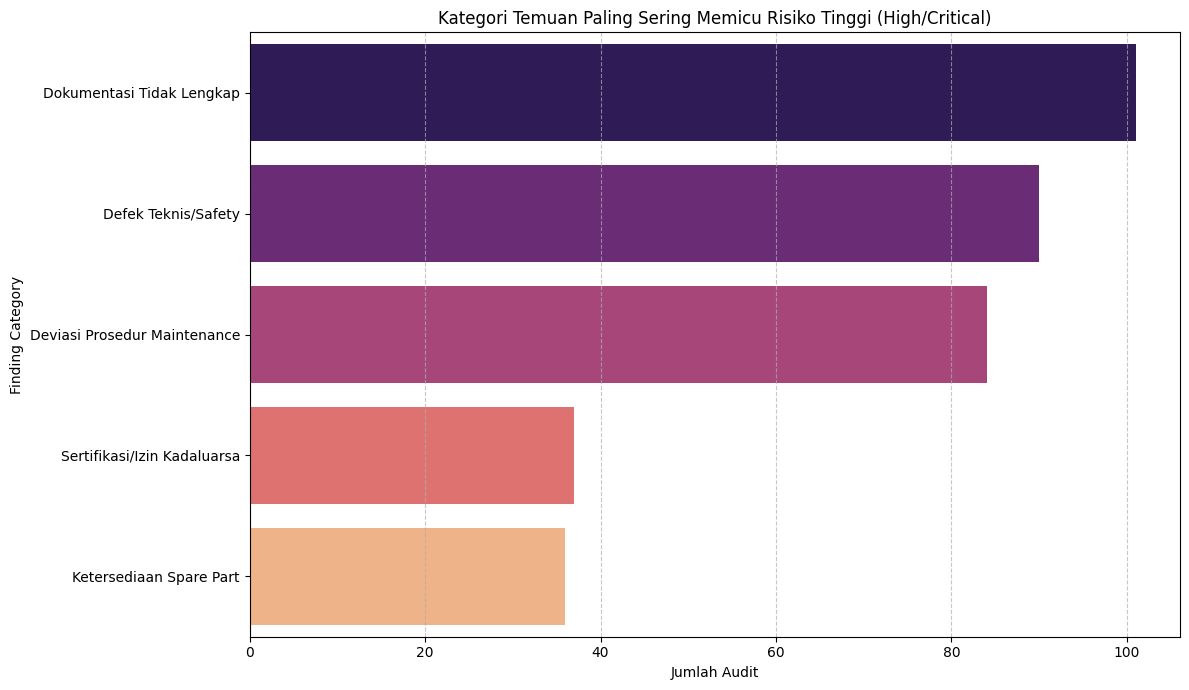

In [20]:
#Filter data dengan Risk_Level in ['High', 'Critical']
high_risk_findings = df[df['Risk_Level'].isin(['High', 'Critical'])]

#Hitung value_counts pada Findings_Category
finding_cat_counts = high_risk_findings['Finding_Category'].value_counts()

print('Kategori Temuan Paling Sering Memicu Risiko Tinggi:')
print(finding_cat_counts)

#Visualisasi
plt.figure(figsize=(12, 7))
sns.barplot(x=finding_cat_counts.values, y=finding_cat_counts.index,
            palette='magma', hue=finding_cat_counts.index, legend=False)
plt.title('Kategori Temuan Paling Sering Memicu Risiko Tinggi (High/Critical)')
plt.xlabel('Jumlah Audit')
plt.ylabel('Finding Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 5.5 Insight dari Analisis Risiko:

Dari analisis identifikasi dan evaluasi potensi risiko, kita mendapatkan beberapa temuan kunci:

1.  **Distribusi Tingkat Risiko:** Sebagian besar temuan audit berada pada tingkat risiko `Low`, namun ada jumlah signifikan temuan `High` dan `Critical` yang memerlukan perhatian khusus.

2.  **Risk Matrix: Kombinasi Site x Equipment Paling Berisiko:**
    Heatmap Risk Matrix adalah alat yang paling powerful dan menunjukkan kombinasi site dan kategori peralatan dengan proporsi risiko `High`/`Critical` tertinggi. Beberapa *hotspot* yang paling menonjol adalah:
    *   **Gudang Logistik Cikarang:** Menunjukkan proporsi risiko tinggi pada **Genset (63.6%)** dan **Sprinkler (57.1%)**.
    *   **RS Harapan Sehat:** Menunjukkan risiko tinggi pada **Genset (53.9%)** dan **Sprinkler (46.0%)**.
    *   **Apartemen Green Valley:** Memiliki risiko tinggi pada **Genset (50.0%)** dan **Sprinkler (50.0%)**.
    *   **Menara Bisnis Selatan:** Menonjol dengan risiko tinggi pada **Sprinkler (54.5%)**.
    *   **RS Medika Utama:** Memiliki risiko tinggi pada **Genset (50.0%)**.
    Area-area ini harus menjadi prioritas utama untuk audit dan tindakan perbaikan.

3.  **Hubungan Usia Peralatan dengan Risiko:** Dari boxplot, terlihat ada kecenderungan bahwa peralatan dengan tingkat risiko `High` dan `Critical` memiliki rentang usia yang sedikit lebih tua atau median usia yang serupa dibandingkan dengan `Low` dan `Medium`. Meskipun tidak selalu menunjukkan korelasi linear yang kuat, ini mengindikasikan bahwa usia peralatan mungkin berkontribusi terhadap peningkatan risiko, terutama pada peralatan yang sangat tua, mendukung dugaan bahwa peralatan yang lebih tua cenderung memiliki risiko lebih tinggi dan mungkin memerlukan investasi capex untuk penggantian.

4.  **Kategori Temuan Paling Sering Memicu Risiko Tinggi:** Tiga kategori temuan yang paling sering ditemukan pada audit dengan risiko `High` atau `Critical` adalah:
    *   **Dokumentasi Tidak Lengkap (101 temuan)**
    *   **Defek Teknis/Safety (90 temuan)**
    *   **Deviasi Prosedur Maintenance (84 temuan)**
    Ini menyoroti bahwa masalah non-teknis seperti dokumentasi dan kepatuhan prosedur, selain masalah teknis, merupakan pemicu signifikan risiko tinggi. Audit harus memfokuskan perhatian pada memastikan dokumentasi yang lengkap dan kepatuhan prosedur yang ketat untuk mengurangi risiko.

## 6. Kesimpulan & Jembatan ke Analisis Berikutnya

Berdasarkan analisis *compliance* dan identifikasi risiko yang telah dilakukan pada Bagian 1 ini, kita dapat menyimpulkan:

*   **Kesesuaian Implementasi Prosedur:** Site **RS Harapan Sehat**, **Gudang Logistik Cikarang**, dan **Apartemen Green Valley** menunjukkan tingkat ketidaksesuaian prosedur tertinggi. Selain itu, kategori peralatan **Genset** dan **HVAC** juga memiliki *Non-Compliant Rate* yang paling tinggi. Tren kepatuhan secara keseluruhan sempat memburuk signifikan di Q3 2023 namun menunjukkan perbaikan bertahap di kuartal-kuartal berikutnya.

*   **Identifikasi & Evaluasi Potensi Risiko:** Kombinasi site dan peralatan yang paling berisiko tinggi (terutama `High` dan `Critical`) adalah:
    *   **Gudang Logistik Cikarang** untuk **Genset** dan **Sprinkler**.
    *   **RS Harapan Sehat** untuk **Genset** dan **Sprinkler**.
    *   **Apartemen Green Valley** untuk **Genset** dan **Sprinkler**.
    *   **Menara Bisnis Selatan** untuk **Sprinkler**.
    *   **RS Medika Utama** untuk **Genset**.

    Dugaan bahwa usia peralatan berkorelasi dengan risiko tinggi juga didukung, mengindikasikan perlunya evaluasi `capex` untuk penggantian alat. Kategori temuan seperti **Dokumentasi Tidak Lengkap**, **Defek Teknis/Safety**, dan **Deviasi Prosedur Maintenance** adalah pemicu utama risiko tinggi.

**Rekomendasi Prioritas Audit:**

Dari temuan di atas, tim audit internal direkomendasikan untuk memfokuskan sumber daya dan upaya audit pada:
1.  **Site:** RS Harapan Sehat, Gudang Logistik Cikarang, Apartemen Green Valley.
2.  **Kategori Peralatan:** Genset dan Sprinkler.
3.  **Area Temuan:** Memastikan kelengkapan dokumentasi dan kepatuhan prosedur maintenance yang ketat.

### Jembatan ke Analisis Berikutnya:

Analisis yang telah kita lakukan memberikan gambaran komprehensif tentang area-area kunci yang memerlukan perhatian segera. Untuk tindak lanjut, dua poin penting dari *job description* audit internal, yaitu **konfirmasi temuan ke pihak terkait & *follow-up*** serta **investigasi mendalam**, akan dianalisis lebih lanjut pada bagian berikutnya dari portofolio audit ini. Bagian selanjutnya akan berfokus pada **Analisis Penyelesaian Temuan dan Pengelolaan Tindak Lanjut**, yang akan melibatkan penggunaan alat seperti Excel dan Power BI untuk visualisasi dan pelaporan yang lebih interaktif.